<a href="https://colab.research.google.com/github/harishg43/Warehouse_efficiency_insight/blob/main/Warehouse_Efficiency_Insight_Assessment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Install any libraries not already present in Google Colab.
%pip -q install xlsxwriter python-pptx scikit-learn


In [4]:
from pathlib import Path
import os, re, zipfile, shutil, json, math, unicodedata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.enum.text import PP_ALIGN
from pptx.dml.color import RGBColor

from IPython.display import display, Markdown

try:
    from google.colab import files as colab_files
    IN_COLAB = True
except Exception:
    IN_COLAB = False

BASE_DIR = Path('/content/warehouse_assessment') if IN_COLAB else (Path.cwd() / 'warehouse_assessment')
INPUT_DIR = BASE_DIR / 'input'
OUTPUT_DIR = BASE_DIR / 'outputs'
CHART_DIR = OUTPUT_DIR / 'charts'
for folder in [INPUT_DIR, OUTPUT_DIR, CHART_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print('Environment:', 'Google Colab' if IN_COLAB else 'Local Python')
print('Input folder:', INPUT_DIR)
print('Output folder:', OUTPUT_DIR)


Environment: Google Colab
Input folder: /content/warehouse_assessment/input
Output folder: /content/warehouse_assessment/outputs


In [5]:
# Upload files in Colab. You can select one or more ZIPs or CSVs together.
if IN_COLAB:
    print('Upload your dataset ZIP or CSV files now. For the current conversation dataset, upload archive (2).zip.')
    print('If you also want to test the assessment-aligned practice data, upload warehouse_order_picking_assessment_dataset.zip too (synthetic data).')
    uploaded_files = colab_files.upload()
    for file_name, payload in uploaded_files.items():
        destination = INPUT_DIR / Path(file_name).name
        destination.write_bytes(payload)
        print('Saved:', destination.name)
else:
    print('Non-Colab run: place your ZIP/CSV files in', INPUT_DIR)
    print('The notebook will also look for ZIP/CSV files in the current working directory.')
    for src in Path.cwd().glob('*.zip'):
        dst = INPUT_DIR / src.name
        if src.resolve() != dst.resolve() and not dst.exists():
            shutil.copy2(src, dst)
    for src in Path.cwd().glob('*.csv'):
        dst = INPUT_DIR / src.name
        if src.resolve() != dst.resolve() and not dst.exists():
            shutil.copy2(src, dst)

# Extract every uploaded ZIP safely into a dedicated subfolder.
for zip_path in list(INPUT_DIR.glob('*.zip')):
    extract_folder = INPUT_DIR / (zip_path.stem.replace(' ', '_') + '_extracted')
    extract_folder.mkdir(parents=True, exist_ok=True)
    try:
        with zipfile.ZipFile(zip_path, 'r') as zf:
            for member in zf.infolist():
                target = (extract_folder / member.filename).resolve()
                if not str(target).startswith(str(extract_folder.resolve()) + os.sep) and target != extract_folder.resolve():
                    continue
                zf.extract(member, extract_folder)
        print(f'Extracted: {zip_path.name} -> {extract_folder.name}')
    except zipfile.BadZipFile:
        print('WARNING: Could not read ZIP file:', zip_path.name)

csv_paths = sorted(set(INPUT_DIR.rglob('*.csv')))
inventory = []
for p in csv_paths:
    try:
        tmp = pd.read_csv(p, nrows=5, encoding='utf-8-sig')
        inventory.append({'file': p.name, 'relative_path': str(p.relative_to(INPUT_DIR)),
                          'columns_in_preview': len(tmp.columns), 'preview_rows': len(tmp)})
    except Exception as exc:
        inventory.append({'file': p.name, 'relative_path': str(p.relative_to(INPUT_DIR)),
                          'columns_in_preview': np.nan, 'preview_rows': np.nan, 'read_error': str(exc)[:180]})

inventory_df = pd.DataFrame(inventory)
print(f'Found {len(csv_paths)} CSV file(s).')
display(inventory_df)
inventory_df.to_csv(OUTPUT_DIR / 'input_file_inventory.csv', index=False)

if not csv_paths:
    raise FileNotFoundError('No CSV files found. Upload a ZIP containing CSVs or upload CSV files, then rerun this cell.')


Upload your dataset ZIP or CSV files now. For the current conversation dataset, upload archive (2).zip.
If you also want to test the assessment-aligned practice data, upload warehouse_order_picking_assessment_dataset.zip too (synthetic data).


Saving warehouse_order_picking_assessment_dataset.zip to warehouse_order_picking_assessment_dataset.zip
Saved: warehouse_order_picking_assessment_dataset.zip
Extracted: warehouse_order_picking_assessment_dataset.zip -> warehouse_order_picking_assessment_dataset_extracted
Found 2 CSV file(s).


,file,relative_path,columns_in_preview,preview_rows
0,warehouse_order_picking_clean.csv,warehouse_order_picking_assessment_dataset_ext...,14,5
1,warehouse_order_picking_raw.csv,warehouse_order_picking_assessment_dataset_ext...,14,5


In [7]:
def normalize_name(value):
    value = unicodedata.normalize('NFKD', str(value)).encode('ascii', 'ignore').decode('ascii')
    value = value.strip().lower()
    value = re.sub(r'[^a-z0-9]+', '_', value).strip('_')
    return value

def read_csv_clean_headers(path):
    try:
        frame = pd.read_csv(path, encoding='utf-8-sig', low_memory=False)
    except UnicodeDecodeError:
        frame = pd.read_csv(path, encoding='latin-1', low_memory=False)
    frame.columns = [normalize_name(c) for c in frame.columns]
    return frame

def is_unique_key(series):
    nonnull = series.dropna()
    return len(nonnull) > 0 and nonnull.nunique() == len(nonnull)

def safe_join_key(left, right, entity):
    common = set(left.columns).intersection(right.columns)
    entity_words = {
        'order': ['order', 'pedido', 'despacho'],
        'worker': ['worker', 'picker', 'operario', 'empleado', 'personal'],
        'zone': ['zone', 'zona'],
        'item': ['item', 'product', 'producto', 'articulo'],
    }.get(entity, [entity])
    scored = []
    for key in common:
        if key in {'id', 'name', 'date', 'timestamp'}:
            continue
        if not ('id' in key or key.startswith('id_') or key.endswith('_id')):
            continue
        score = sum(word in key for word in entity_words)
        if score:
            scored.append((score, key))
    scored.sort(reverse=True)
    for _, key in scored:
        if is_unique_key(right[key]):
            return key
    return None

def load_relational_tables(paths):
    by_base = {p.name.lower(): p for p in paths}
    expected = ['orders.csv', 'picks.csv', 'items.csv', 'workers.csv', 'zones.csv']
    if not all(name in by_base for name in expected):
        return None, []
    tables = {Path(name).stem: read_csv_clean_headers(by_base[name]) for name in expected}
    notes = [f'Loaded {name}: {tables[Path(name).stem].shape[0]} rows × {tables[Path(name).stem].shape[1]} columns.' for name in expected]
    merged = tables['picks'].copy()
    # Join orders first, then worker and zone dimensions. Items are merged only if picks has a shared item identifier.
    join_plan = [('orders', 'order'), ('workers', 'worker'), ('zones', 'zone'), ('items', 'item')]
    for table_name, entity in join_plan:
        right = tables[table_name]
        key = safe_join_key(merged, right, entity)
        if key is None:
            notes.append(f'SKIPPED join to {table_name}.csv: no safe, shared {entity} identifier was found (or the lookup key was not unique).')
            continue
        overlapping = [c for c in right.columns if c in merged.columns and c != key]
        right2 = right.rename(columns={c: f'{c}_{table_name}' for c in overlapping})
        before = len(merged)
        try:
            merged = merged.merge(right2, on=key, how='left', validate='many_to_one')
            notes.append(f'Joined {table_name}.csv on {key}; rows {before} -> {len(merged)}.')
        except Exception as exc:
            notes.append(f'SKIPPED join to {table_name}.csv on {key}: {str(exc)[:160]}')
    return merged, notes

# Prefer college-style five-table data when all five files are available.
relational_df, join_notes = load_relational_tables(csv_paths)
assessment_clean_candidates = [p for p in csv_paths if p.name.lower() in {
    'warehouse_order_picking_clean.csv', 'warehouse_order_picking_cleaned.csv'}]
assessment_raw_candidates = [p for p in csv_paths if p.name.lower() == 'warehouse_order_picking_raw.csv']
dispatch_candidates = [p for p in csv_paths if p.name.lower() == 'despachos_clean.csv']

if relational_df is not None:
    raw_df = relational_df.copy()
    source_path = None
    source_label = 'Five-table relational dataset (orders/picks/items/workers/zones)'
    source_mode = 'relational'
    print('\n'.join(join_notes))
elif assessment_clean_candidates:
    source_path = assessment_clean_candidates[0]
    raw_df = read_csv_clean_headers(source_path)
    source_label = source_path.name
    source_mode = 'assessment_aligned_practice'
elif dispatch_candidates:
    source_path = dispatch_candidates[0]
    raw_df = read_csv_clean_headers(source_path)
    source_label = source_path.name
    source_mode = 'uploaded_dispatch_dataset'
elif assessment_raw_candidates:
    source_path = assessment_raw_candidates[0]
    raw_df = read_csv_clean_headers(source_path)
    source_label = source_path.name
    source_mode = 'assessment_aligned_raw_practice'
else:
    # If no well-known filename exists, choose the largest CSV by byte size as a transparent fallback.
    source_path = max(csv_paths, key=lambda p: p.stat().st_size)
    raw_df = read_csv_clean_headers(source_path)
    source_label = source_path.name
    source_mode = 'fallback_single_csv'

print('Selected source:', source_label)
print('Source mode:', source_mode)
print('Initial dimensions:', raw_df.shape)
print('Columns:', raw_df.columns.tolist())
display(raw_df.head())

if source_mode == 'uploaded_dispatch_dataset':
    print('\nDATASET SCOPE WARNING: This file appears to describe dispatch/route preparation. It does not have all required warehouse-picking fields. The notebook will analyze what exists and mark absent dimensions as unavailable.')
elif source_mode == 'assessment_aligned_practice' or source_mode == 'assessment_aligned_raw_practice':
    print('\nSYNTHETIC PRACTICE DATASET NOTICE: This file is a generated practice dataset, not real-world collected warehouse data. Label it accordingly in your submission.')


Selected source: warehouse_order_picking_clean.csv
Source mode: assessment_aligned_practice
Initial dimensions: (1200, 14)
Columns: ['order_id', 'order_datetime', 'zone', 'shift', 'item_count', 'item_category', 'picker_id', 'worker_experience_years', 'distance_travelled_m', 'congestion_level', 'queue_time_min', 'picking_time_min', 'order_processing_time_min', 'delay_flag']


,order_id,order_datetime,zone,shift,item_count,item_category,picker_id,worker_experience_years,distance_travelled_m,congestion_level,queue_time_min,picking_time_min,order_processing_time_min,delay_flag
0,ORD100001,2026-03-26 22:38:00,B,Afternoon,19,Clothing,PK038,4.8,403.2,Medium,5.4,27.4,39.2,Yes
1,ORD100002,2026-04-13 05:47:00,C,Afternoon,6,Home Goods,PK017,2.3,380.2,Low,0.0,19.4,22.1,No
2,ORD100003,2026-04-02 20:52:00,E,Afternoon,6,Electronics,PK022,8.4,185.3,Low,3.1,16.2,26.1,No
3,ORD100004,2026-09-12 07:18:00,A,Night,20,Fragile,PK019,0.6,164.5,Low,3.1,23.8,30.4,No
4,ORD100005,2026-06-30 05:38:00,C,Morning,15,Industrial,PK045,1.8,212.6,Medium,9.2,21.1,34.9,No



SYNTHETIC PRACTICE DATASET NOTICE: This file is a generated practice dataset, not real-world collected warehouse data. Label it accordingly in your submission.


In [8]:
# Standardize whitespace and case in text values, and retain an audit of the original columns.
raw_df = raw_df.copy()
raw_df.columns = [normalize_name(c) for c in raw_df.columns]
raw_shape = raw_df.shape
raw_duplicates = int(raw_df.duplicated().sum())
raw_missing = raw_df.isna().sum().rename('missing_count').to_frame()
raw_missing['missing_percent'] = (raw_missing['missing_count'] / max(len(raw_df), 1) * 100).round(2)
raw_missing = raw_missing.sort_values(['missing_count', 'missing_percent'], ascending=False)
raw_missing.to_csv(OUTPUT_DIR / 'missingness_before_cleaning.csv', index_label='column')

all_empty_cols = [c for c in raw_df.columns if raw_df[c].isna().all()]
clean_df = raw_df.drop_duplicates().copy()
if all_empty_cols:
    clean_df = clean_df.drop(columns=all_empty_cols, errors='ignore')

# Map dataset-specific column names to assessment-friendly canonical names without deleting originals.
COLUMN_ALIASES = {
    'order_datetime': ['order_datetime', 'timestamp', 'order_timestamp', 'datetime', 'fecha', 'date', 'fecha_pedido'],
    'order_id': ['order_id', 'id_order', 'pedido_id', 'id_pedido', 'id_ruta', 'route_id', 'id_despacho'],
    'item_count': ['item_count', 'items_count', 'cant_productos', 'number_of_items', 'items', 'quantity', 'cantidad', 'cantidad_items'],
    'picking_time_min': ['picking_time_min', 'picking_time_minutes', 'pick_time_min', 'pick_duration_min', 'tiempo_preparacion_minutos', 'preparation_time_min', 'duration_min'],
    'zone': ['zone', 'zone_id', 'zona', 'zona_id', 'warehouse_zone', 'zona_pick'],
    'shift': ['shift', 'work_shift', 'turno', 'worker_shift'],
    'worker_experience_years': ['worker_experience_years', 'experience_years', 'years_experience', 'experiencia_anos', 'anios_experiencia'],
    'experience_band': ['experience_band', 'experience_group', 'experience_level', 'banda_experiencia', 'experiencia_banda'],
    'item_category': ['item_category', 'category', 'categoria', 'categoria_articulo', 'product_category'],
    'queue_time_min': ['queue_time_min', 'queue_time', 'waiting_time_min', 'waiting_time', 'tiempo_espera', 'tiempo_cola_min'],
    'distance_travelled_m': ['distance_travelled_m', 'distance_m', 'distance', 'distancia_m', 'distancia'],
    'congestion_level': ['congestion_level', 'congestion', 'congestion_category', 'nivel_congestion'],
    'picker_id': ['picker_id', 'picker', 'worker_id', 'id_worker', 'operario', 'id_operario'],
    'priority': ['priority', 'order_priority', 'prioridad'],
    'item_size': ['item_size', 'size', 'tamano', 'talla'],
    'storage_class': ['storage_class', 'storage_type', 'clase_almacenamiento'],
    'start_time': ['start_time', 'start', 'pick_start', 'tiempo_inicio_ruta', 'hora_inicio', 'inicio'],
    'finish_time': ['finish_time', 'finish', 'end_time', 'pick_finish', 'tiempo_fin_ruta', 'hora_fin', 'fin'],
    'difficulty': ['difficulty', 'mi_dificultad', 'dificultad'],
    'day_of_week_source': ['day_of_week', 'dia_semana', 'weekday'],
    'month_source': ['month', 'mes'],
}

for canonical, choices in COLUMN_ALIASES.items():
    source = next((c for c in choices if c in clean_df.columns), None)
    if source and canonical not in clean_df.columns:
        clean_df[canonical] = clean_df[source]

# Convert dates and numeric fields safely.
if 'order_datetime' in clean_df.columns:
    clean_df['order_datetime'] = pd.to_datetime(clean_df['order_datetime'], errors='coerce')
for col in ['item_count', 'picking_time_min', 'worker_experience_years', 'queue_time_min', 'distance_travelled_m']:
    if col in clean_df.columns:
        clean_df[col] = pd.to_numeric(clean_df[col], errors='coerce')

# Derive picking duration from start/finish when a precomputed target is absent.
if 'picking_time_min' not in clean_df.columns and {'start_time', 'finish_time'}.issubset(clean_df.columns):
    st_text = clean_df['start_time'].astype('string').str.strip()
    en_text = clean_df['finish_time'].astype('string').str.strip()
    st = pd.to_datetime(st_text, errors='coerce')
    en = pd.to_datetime(en_text, errors='coerce')
    duration = (en - st).dt.total_seconds() / 60
    time_only = st_text.str.match(r'^\d{1,2}:\d{2}(:\d{2})?$', na=False) & en_text.str.match(r'^\d{1,2}:\d{2}(:\d{2})?$', na=False)
    duration = duration.where(~(time_only & (duration < 0)), duration + 24 * 60)
    clean_df['picking_time_min'] = duration
    print('Derived picking_time_min from start_time and finish_time where possible.')

# Use date-derived fields when a usable datetime is present.
if 'order_datetime' in clean_df.columns:
    clean_df['order_month'] = clean_df['order_datetime'].dt.month
    clean_df['order_month_name'] = clean_df['order_datetime'].dt.month_name()
    clean_df['order_day_of_week'] = clean_df['order_datetime'].dt.day_name()
    clean_df['is_weekend'] = clean_df['order_datetime'].dt.dayofweek.ge(5).astype('Int64')
    clean_df['order_hour'] = clean_df['order_datetime'].dt.hour.astype('Int64')

# Normalize category labels; don't fabricate missing time values.
for col in clean_df.select_dtypes(include=['object', 'string']).columns:
    clean_df[col] = clean_df[col].map(lambda x: x.strip() if isinstance(x, str) else x)
for col in ['zone', 'shift', 'item_category', 'experience_band', 'congestion_level', 'difficulty', 'priority']:
    if col in clean_df.columns:
        clean_df[col] = clean_df[col].astype('string').str.strip().replace({'': pd.NA})
if 'zone' in clean_df.columns:
    clean_df['zone'] = clean_df['zone'].str.upper()

negative_target_count = 0
if 'picking_time_min' in clean_df.columns:
    negative_target_count = int((clean_df['picking_time_min'] < 0).sum())
    # Negative duration is physically invalid; exclude those records from the cleaned analytical table.
    clean_df = clean_df.loc[clean_df['picking_time_min'].isna() | (clean_df['picking_time_min'] >= 0)].copy()

# Impute ordinary predictor columns, but preserve missing target/start/finish/datetime values.
protected_tokens = ('time', 'timestamp', 'datetime', 'date', 'start', 'finish', 'hora', 'tiempo_inicio', 'tiempo_fin')
identifier_tokens = ('id', 'order_id', 'route_id', 'picker_id')
for col in clean_df.columns:
    if col == 'picking_time_min' or any(t in col for t in protected_tokens) or col in {'order_datetime'}:
        continue
    if any(t in col for t in identifier_tokens):
        continue
    if pd.api.types.is_numeric_dtype(clean_df[col]):
        med = clean_df[col].median()
        if pd.notna(med):
            clean_df[col] = clean_df[col].fillna(med)
    elif clean_df[col].isna().any():
        mode_vals = clean_df[col].mode(dropna=True)
        fill_value = mode_vals.iloc[0] if len(mode_vals) else 'Unknown'
        clean_df[col] = clean_df[col].fillna(fill_value)

clean_missing = clean_df.isna().sum().rename('missing_count').to_frame()
clean_missing['missing_percent'] = (clean_missing['missing_count'] / max(len(clean_df), 1) * 100).round(2)
clean_missing = clean_missing.sort_values(['missing_count', 'missing_percent'], ascending=False)
clean_missing.to_csv(OUTPUT_DIR / 'missingness_after_cleaning.csv', index_label='column')

quality_rows = [
    {'check': 'Raw rows', 'value': raw_shape[0], 'notes': 'Rows before cleaning'},
    {'check': 'Raw columns', 'value': raw_shape[1], 'notes': 'Columns before cleaning'},
    {'check': 'Exact duplicate rows found', 'value': raw_duplicates, 'notes': 'Exact duplicate rows removed'},
    {'check': 'Rows after duplicate removal / cleaning', 'value': len(clean_df), 'notes': 'After removing empty columns, exact duplicates, and negative target durations'},
    {'check': 'All-empty columns dropped', 'value': len(all_empty_cols), 'notes': ', '.join(all_empty_cols) if all_empty_cols else 'None'},
    {'check': 'Negative target durations found', 'value': negative_target_count, 'notes': 'Negative durations are excluded from analysis'},
    {'check': 'Columns with missing values after cleaning', 'value': int((clean_df.isna().sum() > 0).sum()), 'notes': 'Missing timestamp fields are preserved where unknown'},
]
quality_df = pd.DataFrame(quality_rows)
quality_df.to_csv(OUTPUT_DIR / 'data_quality_summary.csv', index=False)

# IQR outlier report: flag only, do not auto-delete plausible extremes.
outlier_rows = []
for col in clean_df.select_dtypes(include=np.number).columns:
    if col in {'order_id', 'id_ruta', 'route_id'} or clean_df[col].nunique(dropna=True) <= 2:
        continue
    series = clean_df[col].dropna()
    if len(series) < 8:
        continue
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((series < lower) | (series > upper)).sum())
    outlier_rows.append({'column': col, 'q1': q1, 'q3': q3, 'iqr': iqr,
                         'lower_bound': lower, 'upper_bound': upper,
                         'outlier_count': count, 'outlier_percent': round(count / len(series) * 100, 2),
                         'treatment': 'Flag for review; retained unless confirmed invalid'})
outlier_df = pd.DataFrame(outlier_rows)
outlier_df.to_csv(OUTPUT_DIR / 'outlier_report.csv', index=False)

clean_df.to_csv(OUTPUT_DIR / 'cleaned_dataset.csv', index=False)
print('Cleaning completed.')
display(quality_df)
display(clean_missing.head(15))
display(outlier_df.sort_values('outlier_count', ascending=False).head(15) if len(outlier_df) else outlier_df)
print('Cleaned data shape:', clean_df.shape)


Cleaning completed.


,check,value,notes
0,Raw rows,1200,Rows before cleaning
1,Raw columns,14,Columns before cleaning
2,Exact duplicate rows found,0,Exact duplicate rows removed
3,Rows after duplicate removal / cleaning,1200,"After removing empty columns, exact duplicates..."
4,All-empty columns dropped,0,None
5,Negative target durations found,0,Negative durations are excluded from analysis
6,Columns with missing values after cleaning,0,Missing timestamp fields are preserved where u...


,missing_count,missing_percent
order_id,0,0.0
order_datetime,0,0.0
zone,0,0.0
shift,0,0.0
item_count,0,0.0
item_category,0,0.0
picker_id,0,0.0
worker_experience_years,0,0.0
distance_travelled_m,0,0.0
congestion_level,0,0.0


,column,q1,q3,iqr,lower_bound,upper_bound,outlier_count,outlier_percent,treatment
1,worker_experience_years,2.0,5.300,3.300,-2.9500,10.2500,37,3.08,Flag for review; retained unless confirmed inv...
3,queue_time_min,1.3,6.600,5.300,-6.6500,14.5500,14,1.17,Flag for review; retained unless confirmed inv...
5,order_processing_time_min,26.5,39.300,12.800,7.3000,58.5000,2,0.17,Flag for review; retained unless confirmed inv...
4,picking_time_min,18.6,29.500,10.900,2.2500,45.8500,2,0.17,Flag for review; retained unless confirmed inv...
2,distance_travelled_m,152.3,368.775,216.475,-172.4125,693.4875,0,0.00,Flag for review; retained unless confirmed inv...
0,item_count,9.0,23.000,14.000,-12.0000,44.0000,0,0.00,Flag for review; retained unless confirmed inv...
6,order_month,3.0,7.000,4.000,-3.0000,13.0000,0,0.00,Flag for review; retained unless confirmed inv...
7,order_hour,5.0,18.000,13.000,-14.5000,37.5000,0,0.00,Flag for review; retained unless confirmed inv...


Cleaned data shape: (1200, 19)


In [9]:
# Feature engineering, only when source fields are available.
if 'item_count' in clean_df.columns:
    values = clean_df['item_count']
    valid = values.dropna()
    if len(valid) >= 3 and valid.nunique() >= 3:
        try:
            clean_df['order_size_group'] = pd.qcut(values, q=3, labels=['Small', 'Medium', 'Large'], duplicates='drop')
        except Exception:
            clean_df['order_size_group'] = pd.cut(values, bins=3, labels=['Small', 'Medium', 'Large'], include_lowest=True)
    elif len(valid):
        clean_df['order_size_group'] = 'Single group'
    else:
        clean_df['order_size_group'] = pd.NA

if 'worker_experience_years' in clean_df.columns:
    clean_df['experience_group'] = pd.cut(
        clean_df['worker_experience_years'],
        bins=[-np.inf, 2, 5, np.inf], labels=['Beginner (<=2y)', 'Intermediate (2-5y)', 'Experienced (>5y)']
    )
elif 'experience_band' in clean_df.columns:
    clean_df['experience_group'] = clean_df['experience_band'].astype('string')

if {'item_count', 'picking_time_min'}.issubset(clean_df.columns):
    clean_df['picking_efficiency_items_per_min'] = clean_df['item_count'] / clean_df['picking_time_min'].replace(0, np.nan)
if 'queue_time_min' in clean_df.columns:
    valid_q = clean_df['queue_time_min'].dropna()
    if len(valid_q) >= 3 and valid_q.nunique() >= 3:
        try:
            clean_df['queue_time_group'] = pd.qcut(clean_df['queue_time_min'], q=3, labels=['Low', 'Medium', 'High'], duplicates='drop')
        except Exception:
            clean_df['queue_time_group'] = pd.cut(clean_df['queue_time_min'], bins=3, labels=['Low', 'Medium', 'High'], include_lowest=True)

clean_df.to_csv(OUTPUT_DIR / 'cleaned_dataset.csv', index=False)

has_target = 'picking_time_min' in clean_df.columns and clean_df['picking_time_min'].notna().sum() > 0
coverage_specs = [
    ('Which zones take longer to pick?', ['zone', 'picking_time_min'], 'Compare mean/median picking time by zone.'),
    ('How does item count affect time?', ['item_count', 'picking_time_min'], 'Correlation and scatter plot of item count vs picking time.'),
    ('Which shifts show delays?', ['shift', 'picking_time_min'], 'Compare shift durations; use delay/queue field if available.'),
    ('Does worker experience relate to time?', ['picking_time_min'], 'Requires worker_experience_years or experience_band in addition to target.'),
    ('Which item categories slow picking?', ['item_category', 'picking_time_min'], 'Compare picking time by item category.'),
    ('Where does order processing queue build up?', ['queue_time_min'], 'Requires explicit queue/wait time, or timestamps sufficient to derive it.'),
]
coverage_rows = []
for question, required, approach in coverage_specs:
    if question.startswith('Does worker'):
        required = ['picking_time_min']
        exp_present = ('worker_experience_years' in clean_df.columns) or ('experience_band' in clean_df.columns) or ('experience_group' in clean_df.columns)
        available = has_target and exp_present
        missing = [] if available else ([x for x in required if x not in clean_df.columns] + ([] if exp_present else ['worker_experience_years or experience_band']))
    elif question.startswith('Where does'):
        available = ('queue_time_min' in clean_df.columns and clean_df['queue_time_min'].notna().any()) or ('order_processing_time_min' in clean_df.columns and clean_df['order_processing_time_min'].notna().any())
        missing = [] if available else ['queue_time_min or derivable queue timestamps']
    else:
        available = all(c in clean_df.columns and clean_df[c].notna().any() for c in required)
        missing = [c for c in required if c not in clean_df.columns or not clean_df[c].notna().any()]
    coverage_rows.append({'business_question': question, 'status': 'Available' if available else 'Not available in this dataset',
                          'required_fields_missing': ', '.join(missing), 'suggested_analysis': approach})
coverage_df = pd.DataFrame(coverage_rows)
coverage_df.to_csv(OUTPUT_DIR / 'assessment_question_coverage.csv', index=False)
display(coverage_df)


,business_question,status,required_fields_missing,suggested_analysis
0,Which zones take longer to pick?,Available,,Compare mean/median picking time by zone.
1,How does item count affect time?,Available,,Correlation and scatter plot of item count vs ...
2,Which shifts show delays?,Available,,Compare shift durations; use delay/queue field...
3,Does worker experience relate to time?,Available,,Requires worker_experience_years or experience...
4,Which item categories slow picking?,Available,,Compare picking time by item category.
5,Where does order processing queue build up?,Available,,"Requires explicit queue/wait time, or timestam..."


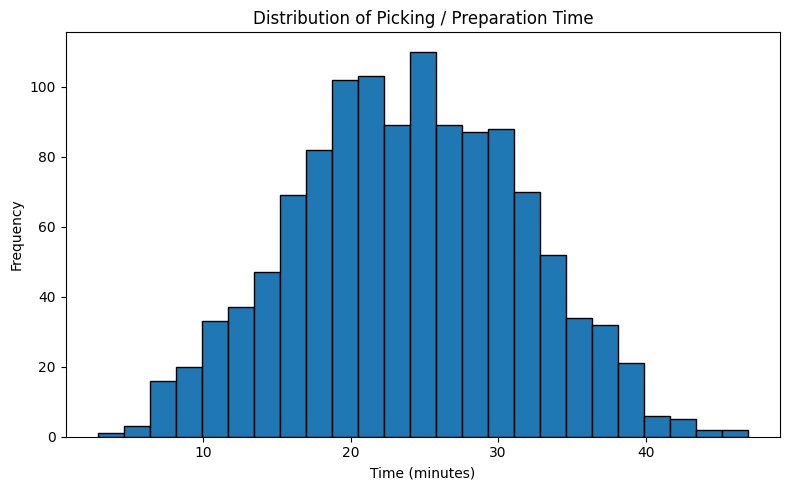

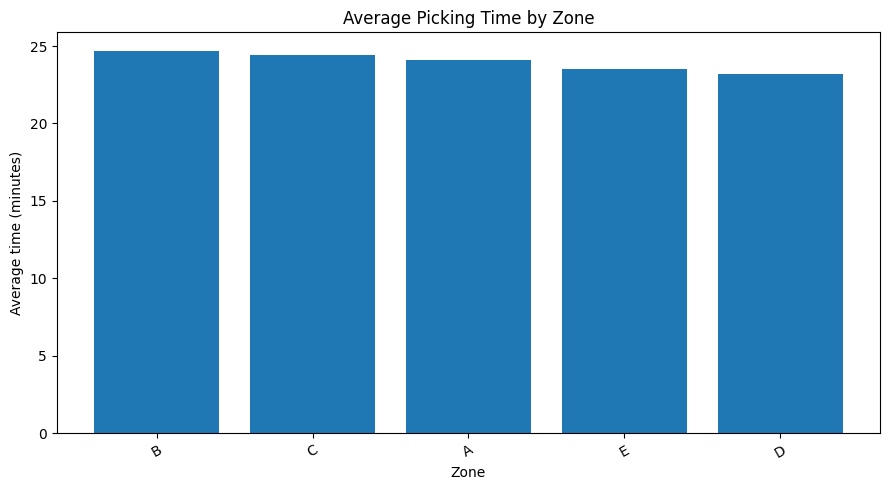

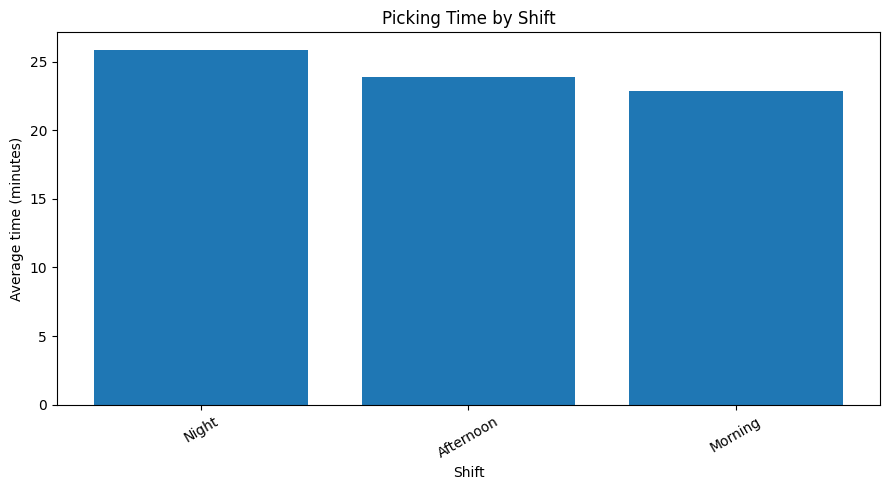

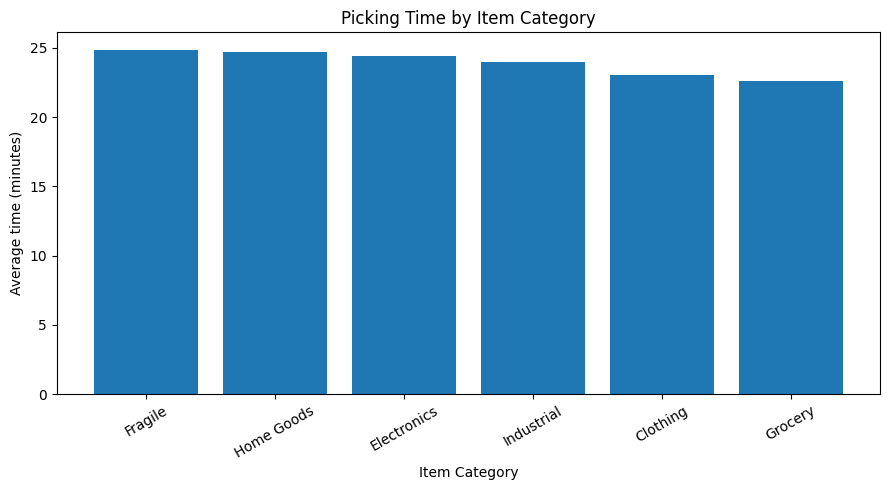

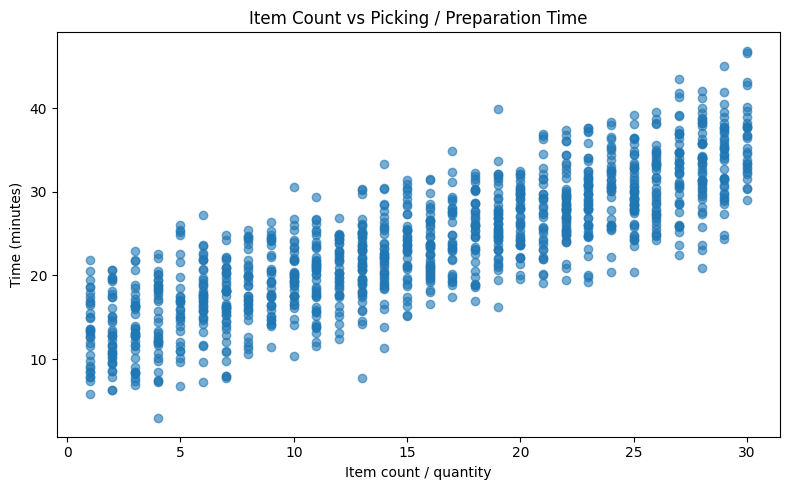

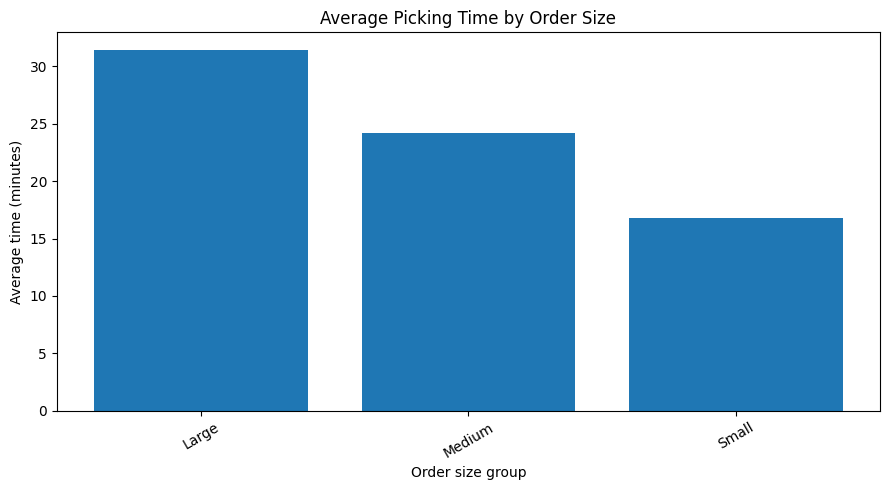

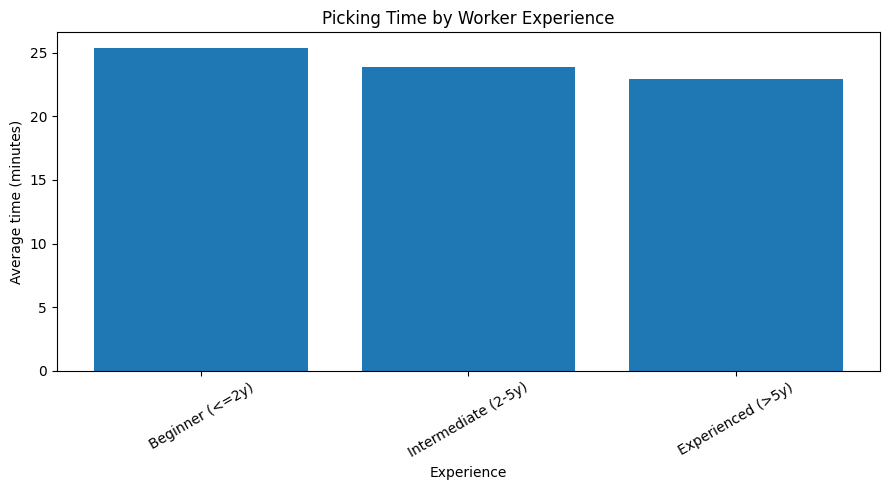

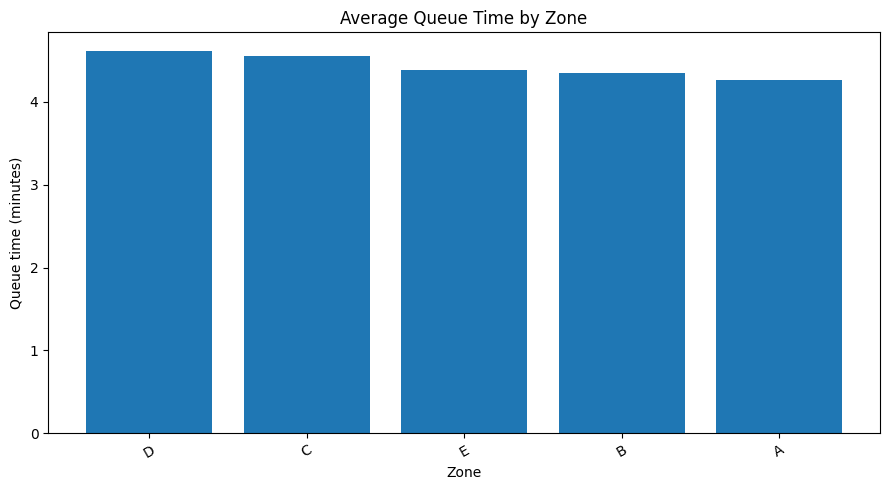

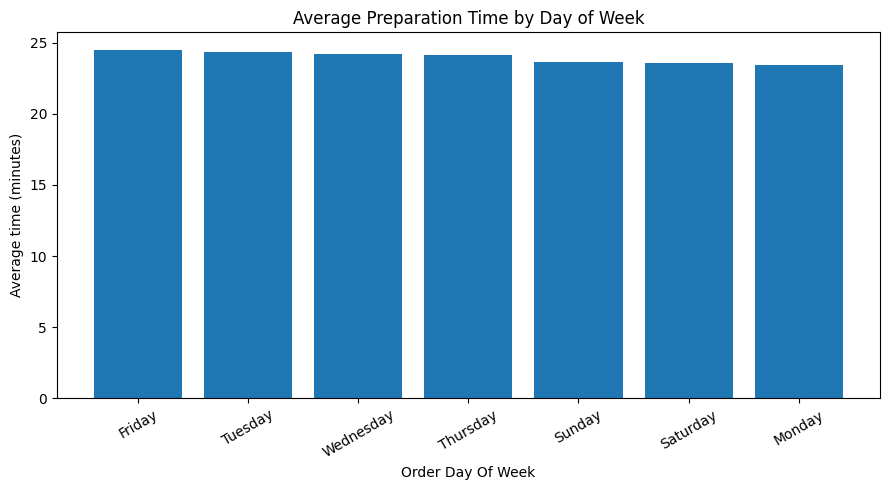

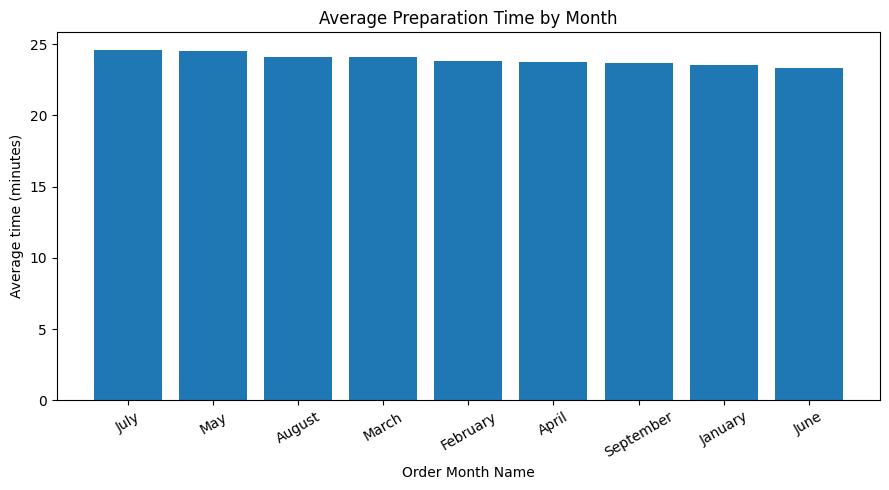

EDA summary:


,metric,value,interpretation
0,record_count_with_target,1200,Records with a usable target duration
1,mean_picking_time_min,23.953,Mean picking/preparation duration in the avail...
2,median_picking_time_min,24.0,Median picking/preparation duration in the ava...
3,std_picking_time_min,7.631324,Standard deviation of picking/preparation dura...
4,max_picking_time_min,46.9,Maximum observed picking/preparation duration;...
5,highest_mean_time_by_zone,B,Mean 24.65 minutes across 222 records
6,lowest_mean_time_by_zone,D,Mean 23.21 minutes across 285 records
7,highest_mean_time_by_shift,Night,Mean 25.84 minutes across 297 records
8,lowest_mean_time_by_shift,Morning,Mean 22.84 minutes across 481 records
9,highest_mean_time_by_item_category,Fragile,Mean 24.88 minutes across 214 records


Charts saved to: /content/warehouse_assessment/outputs/charts


In [10]:
def save_bar_plot(summary, x_col, y_col, title, xlabel, ylabel, filename, rotation=30):
    if summary.empty or x_col not in summary.columns or y_col not in summary.columns:
        return None
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(summary[x_col].astype(str), summary[y_col])
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis='x', rotation=rotation)
    fig.tight_layout()
    path = CHART_DIR / filename
    fig.savefig(path, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    return path

def grouped_summary(frame, group_col, value_col='picking_time_min'):
    if group_col not in frame.columns or value_col not in frame.columns:
        return pd.DataFrame()
    tmp = frame[[group_col, value_col]].copy()
    tmp = tmp.dropna(subset=[group_col, value_col])
    if tmp.empty:
        return pd.DataFrame()
    out = tmp.groupby(group_col, observed=False)[value_col].agg(['count', 'mean', 'median', 'std']).reset_index()
    out.columns = [group_col, 'record_count', 'mean_minutes', 'median_minutes', 'std_minutes']
    return out.sort_values('mean_minutes', ascending=False)

eda_summary_rows = []
if has_target:
    target = clean_df['picking_time_min'].dropna()
    eda_summary_rows += [
        {'metric': 'record_count_with_target', 'value': int(target.shape[0]), 'interpretation': 'Records with a usable target duration'},
        {'metric': 'mean_picking_time_min', 'value': float(target.mean()), 'interpretation': 'Mean picking/preparation duration in the available dataset'},
        {'metric': 'median_picking_time_min', 'value': float(target.median()), 'interpretation': 'Median picking/preparation duration in the available dataset'},
        {'metric': 'std_picking_time_min', 'value': float(target.std()), 'interpretation': 'Standard deviation of picking/preparation duration'},
        {'metric': 'max_picking_time_min', 'value': float(target.max()), 'interpretation': 'Maximum observed picking/preparation duration; inspect before drawing conclusions'},
    ]

# Target distribution.
if has_target:
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.hist(clean_df['picking_time_min'].dropna(), bins=25, edgecolor='black')
    ax.set_title('Distribution of Picking / Preparation Time')
    ax.set_xlabel('Time (minutes)')
    ax.set_ylabel('Frequency')
    fig.tight_layout()
    fig.savefig(CHART_DIR / '01_picking_time_distribution.png', dpi=160, bbox_inches='tight')
    plt.show(); plt.close(fig)

# Six assessment-aligned analyses / alternatives when fields are not present.
summary_tables = {}

def group_chart_or_alternative(primary_group, alternatives, title, filename):
    group_col = primary_group if primary_group in clean_df.columns else next((c for c in alternatives if c in clean_df.columns), None)
    if has_target and group_col:
        s = grouped_summary(clean_df, group_col)
        summary_tables[filename.replace('.png', '')] = s
        save_bar_plot(s, group_col, 'mean_minutes', title if group_col == primary_group else f'{title} (using available field: {group_col})', group_col.replace('_', ' ').title(), 'Average time (minutes)', filename)
        if not s.empty:
            hi = s.iloc[0]
            lo = s.sort_values('mean_minutes').iloc[0]
            eda_summary_rows.append({'metric': f'highest_mean_time_by_{group_col}', 'value': str(hi[group_col]), 'interpretation': f'Mean {hi["mean_minutes"]:.2f} minutes across {int(hi["record_count"])} records'})
            eda_summary_rows.append({'metric': f'lowest_mean_time_by_{group_col}', 'value': str(lo[group_col]), 'interpretation': f'Mean {lo["mean_minutes"]:.2f} minutes across {int(lo["record_count"])} records'})
        return s, group_col
    return pd.DataFrame(), None

zone_summary, zone_used = group_chart_or_alternative('zone', ['difficulty', 'mi_dificultad'], 'Average Picking Time by Zone', '02_picking_time_by_zone.png')
shift_summary, shift_used = group_chart_or_alternative('shift', ['order_day_of_week', 'day_of_week_source'], 'Picking Time by Shift', '03_picking_time_by_shift.png')
category_summary, category_used = group_chart_or_alternative('item_category', ['storage_class', 'item_size', 'difficulty'], 'Picking Time by Item Category', '04_picking_time_by_category.png')

# Order-size analysis / relationship.
if has_target and 'item_count' in clean_df.columns:
    valid_pair = clean_df[['item_count', 'picking_time_min']].dropna()
    if len(valid_pair) >= 3:
        corr = float(valid_pair['item_count'].corr(valid_pair['picking_time_min']))
        eda_summary_rows.append({'metric': 'correlation_item_count_vs_time', 'value': corr, 'interpretation': 'Pearson correlation; association is not proof of causation'})
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.scatter(valid_pair['item_count'], valid_pair['picking_time_min'], alpha=0.6)
        ax.set_title('Item Count vs Picking / Preparation Time')
        ax.set_xlabel('Item count / quantity')
        ax.set_ylabel('Time (minutes)')
        fig.tight_layout()
        fig.savefig(CHART_DIR / '05_item_count_vs_time.png', dpi=160, bbox_inches='tight')
        plt.show(); plt.close(fig)
    if 'order_size_group' in clean_df.columns:
        size_summary = grouped_summary(clean_df, 'order_size_group')
        summary_tables['order_size_analysis'] = size_summary
        save_bar_plot(size_summary, 'order_size_group', 'mean_minutes', 'Average Picking Time by Order Size', 'Order size group', 'Average time (minutes)', '06_order_size_analysis.png')
else:
    size_summary = pd.DataFrame()

# Experience comparison.
experience_group_col = 'experience_group' if 'experience_group' in clean_df.columns else ('experience_band' if 'experience_band' in clean_df.columns else ('worker_experience_years' if 'worker_experience_years' in clean_df.columns else None))
if has_target and experience_group_col:
    experience_summary = grouped_summary(clean_df, experience_group_col)
    summary_tables['experience_analysis'] = experience_summary
    save_bar_plot(experience_summary, experience_group_col, 'mean_minutes', 'Picking Time by Worker Experience', 'Experience', 'Average time (minutes)', '07_experience_analysis.png')
else:
    experience_summary = pd.DataFrame()

# Queue-time summary.
if 'queue_time_min' in clean_df.columns:
    qdf = clean_df.dropna(subset=['queue_time_min'])
    if len(qdf):
        queue_overall = pd.DataFrame([{'metric': 'queue_count', 'value': len(qdf)},
                                      {'metric': 'mean_queue_time_min', 'value': qdf['queue_time_min'].mean()},
                                      {'metric': 'median_queue_time_min', 'value': qdf['queue_time_min'].median()},
                                      {'metric': 'max_queue_time_min', 'value': qdf['queue_time_min'].max()}])
        queue_overall.to_csv(OUTPUT_DIR / 'queue_time_summary.csv', index=False)
        if 'zone' in qdf.columns:
            queue_zone = qdf.groupby('zone', dropna=False)['queue_time_min'].agg(['count', 'mean', 'median']).reset_index().sort_values('mean', ascending=False)
            queue_zone.columns = ['zone', 'record_count', 'mean_queue_time_min', 'median_queue_time_min']
            summary_tables['queue_by_zone'] = queue_zone
            save_bar_plot(queue_zone, 'zone', 'mean_queue_time_min', 'Average Queue Time by Zone', 'Zone', 'Queue time (minutes)', '08_queue_time_by_zone.png')
        else:
            fig, ax = plt.subplots(figsize=(8, 5))
            ax.hist(qdf['queue_time_min'], bins=20, edgecolor='black')
            ax.set_title('Distribution of Queue Time')
            ax.set_xlabel('Queue time (minutes)'); ax.set_ylabel('Frequency')
            fig.tight_layout(); fig.savefig(CHART_DIR / '08_queue_time_distribution.png', dpi=160, bbox_inches='tight'); plt.show(); plt.close(fig)
        eda_summary_rows += [{'metric': r['metric'], 'value': r['value'], 'interpretation': 'Queue time summary'} for _, r in queue_overall.iterrows()]
else:
    queue_overall = pd.DataFrame()

# Date/time trends.
for group_col, title, filename in [('order_day_of_week', 'Average Preparation Time by Day of Week', '09_time_by_weekday.png'),
                                  ('order_month_name', 'Average Preparation Time by Month', '10_time_by_month.png')]:
    if has_target and group_col in clean_df.columns:
        s = grouped_summary(clean_df, group_col)
        summary_tables[group_col] = s
        save_bar_plot(s, group_col, 'mean_minutes', title, group_col.replace('_', ' ').title(), 'Average time (minutes)', filename)

eda_summary_df = pd.DataFrame(eda_summary_rows).drop_duplicates(subset=['metric'], keep='first')
eda_summary_df.to_csv(OUTPUT_DIR / 'eda_summary_statistics.csv', index=False)
for name, table in summary_tables.items():
    if isinstance(table, pd.DataFrame):
        table.to_csv(OUTPUT_DIR / f'{name}.csv', index=False)

print('EDA summary:')
display(eda_summary_df)
print('Charts saved to:', CHART_DIR)


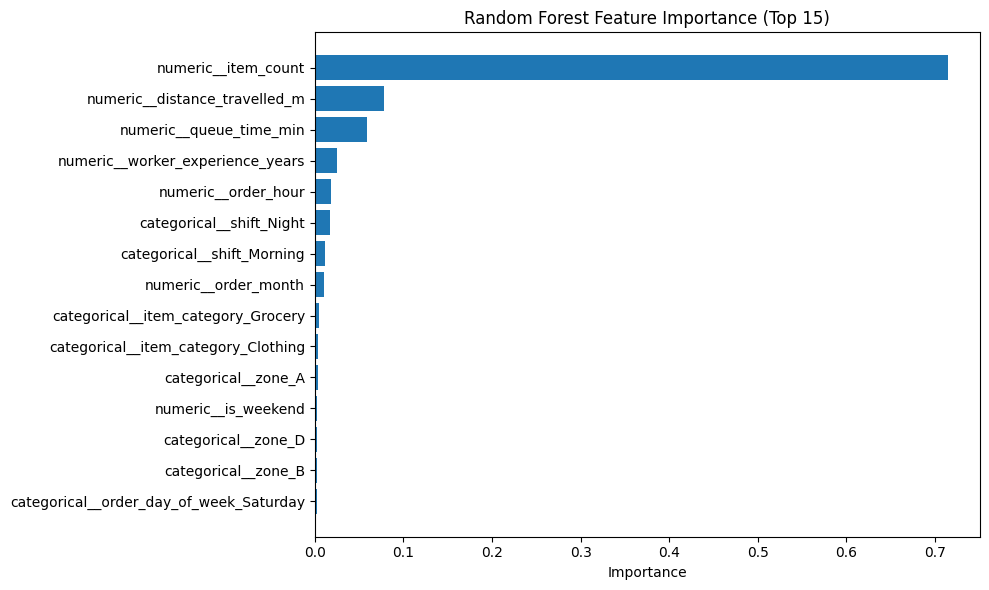

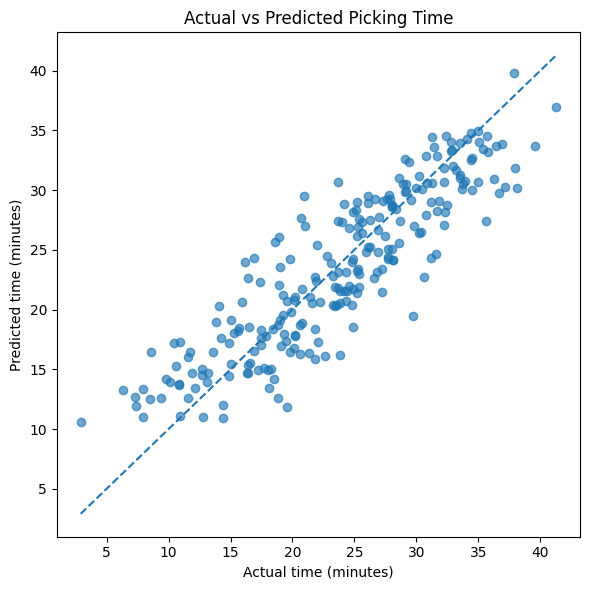

,metric,value
0,algorithm,RandomForestRegressor
1,split,80% train / 20% test; random_state=42
2,training_records,960
3,testing_records,240
4,MAE_minutes,2.917608
5,RMSE_minutes,3.605426
6,R2_score,0.782947
7,predictor_columns,"zone, shift, item_count, item_category, worker..."


,encoded_feature,importance
0,numeric__item_count,0.715002
2,numeric__distance_travelled_m,0.078364
3,numeric__queue_time_min,0.058502
1,numeric__worker_experience_years,0.024640
6,numeric__order_hour,0.018607
14,categorical__shift_Night,0.017445
13,categorical__shift_Morning,0.011503
4,numeric__order_month,0.010139
18,categorical__item_category_Grocery,0.004219
15,categorical__item_category_Clothing,0.003780


Predictors considered: ['zone', 'shift', 'item_count', 'item_category', 'worker_experience_years', 'distance_travelled_m', 'congestion_level', 'queue_time_min', 'order_month', 'order_month_name', 'order_day_of_week', 'is_weekend', 'order_hour']


In [11]:
# Identify potential predictors that are available. Avoid IDs and variables likely derived from the target.
PREDICTOR_CANDIDATES = [
    'zone', 'shift', 'item_count', 'item_category', 'worker_experience_years', 'experience_band',
    'distance_travelled_m', 'congestion_level', 'queue_time_min', 'priority', 'item_size', 'storage_class',
    'difficulty', 'order_month', 'order_month_name', 'order_day_of_week', 'is_weekend', 'order_hour'
]
LEAKAGE_OR_ID_COLUMNS = {
    'picking_time_min', 'picking_efficiency_items_per_min', 'order_processing_time_min',
    'delay_flag', 'velocidad_despacho', 'productividad_jornada', 'tiempo_total_jornada',
    'horas_jornada', 'order_id', 'picker_id', 'id_ruta', 'route_id'
}
feature_cols = [c for c in PREDICTOR_CANDIDATES if c in clean_df.columns and c not in LEAKAGE_OR_ID_COLUMNS]
model_metrics = pd.DataFrame()
feature_importance_df = pd.DataFrame()
model = None

if has_target and len(feature_cols) > 0:
    model_df = clean_df[feature_cols + ['picking_time_min']].copy()
    model_df = model_df.dropna(subset=['picking_time_min'])
    # Drop rows where all predictors are missing; imputation handles the remaining partial missingness.
    model_df = model_df.loc[~model_df[feature_cols].isna().all(axis=1)]
    if len(model_df) >= 25:
        X = model_df[feature_cols].copy()
        y = model_df['picking_time_min'].astype(float)
        numeric_features = [c for c in feature_cols if pd.api.types.is_numeric_dtype(X[c])]
        categorical_features = [c for c in feature_cols if c not in numeric_features]
        numeric_pipeline = Pipeline(steps=[('imputer', SimpleImputer(strategy='median'))])
        categorical_pipeline = Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                                               ('onehot', OneHotEncoder(handle_unknown='ignore'))])
        transformers = []
        if numeric_features:
            transformers.append(('numeric', numeric_pipeline, numeric_features))
        if categorical_features:
            transformers.append(('categorical', categorical_pipeline, categorical_features))
        preprocessor = ColumnTransformer(transformers=transformers, remainder='drop')
        model = Pipeline(steps=[('preprocessor', preprocessor),
                                ('regressor', RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                                                   random_state=42, n_jobs=-1))])
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)
        mae = mean_absolute_error(y_test, predictions)
        rmse = float(np.sqrt(mean_squared_error(y_test, predictions)))
        r2 = r2_score(y_test, predictions) if len(y_test) > 1 else np.nan
        model_metrics = pd.DataFrame([
            {'metric': 'algorithm', 'value': 'RandomForestRegressor'},
            {'metric': 'split', 'value': '80% train / 20% test; random_state=42'},
            {'metric': 'training_records', 'value': len(X_train)},
            {'metric': 'testing_records', 'value': len(X_test)},
            {'metric': 'MAE_minutes', 'value': mae},
            {'metric': 'RMSE_minutes', 'value': rmse},
            {'metric': 'R2_score', 'value': r2},
            {'metric': 'predictor_columns', 'value': ', '.join(feature_cols)},
        ])
        model_metrics.to_csv(OUTPUT_DIR / 'model_performance_metrics.csv', index=False)
        # Use transformed feature names for one-hot encoded categories.
        transformed_names = model.named_steps['preprocessor'].get_feature_names_out()
        importances = model.named_steps['regressor'].feature_importances_
        feature_importance_df = pd.DataFrame({'encoded_feature': transformed_names, 'importance': importances}).sort_values('importance', ascending=False)
        feature_importance_df.to_csv(OUTPUT_DIR / 'feature_selection_importance.csv', index=False)
        fig, ax = plt.subplots(figsize=(10, 6))
        top_imp = feature_importance_df.head(15).sort_values('importance')
        ax.barh(top_imp['encoded_feature'], top_imp['importance'])
        ax.set_title('Random Forest Feature Importance (Top 15)')
        ax.set_xlabel('Importance')
        fig.tight_layout(); fig.savefig(CHART_DIR / '11_feature_importance.png', dpi=160, bbox_inches='tight'); plt.show(); plt.close(fig)
        # Actual vs predicted chart.
        fig, ax = plt.subplots(figsize=(6, 6))
        ax.scatter(y_test, predictions, alpha=0.65)
        lower = float(min(y_test.min(), predictions.min()))
        upper = float(max(y_test.max(), predictions.max()))
        ax.plot([lower, upper], [lower, upper], linestyle='--')
        ax.set_title('Actual vs Predicted Picking Time')
        ax.set_xlabel('Actual time (minutes)'); ax.set_ylabel('Predicted time (minutes)')
        fig.tight_layout(); fig.savefig(CHART_DIR / '12_actual_vs_predicted.png', dpi=160, bbox_inches='tight'); plt.show(); plt.close(fig)
        display(model_metrics)
        display(feature_importance_df.head(15))
    else:
        model_metrics = pd.DataFrame([{'metric': 'status', 'value': f'Not trained: only {len(model_df)} usable records; need at least 25.'}])
        model_metrics.to_csv(OUTPUT_DIR / 'model_performance_metrics.csv', index=False)
else:
    reason = 'No usable picking_time_min target.' if not has_target else 'No suitable predictor columns found.'
    model_metrics = pd.DataFrame([{'metric': 'status', 'value': 'Model not trained: ' + reason}])
    model_metrics.to_csv(OUTPUT_DIR / 'model_performance_metrics.csv', index=False)

if feature_importance_df.empty:
    feature_importance_df = pd.DataFrame([{'encoded_feature': 'No model importance available', 'importance': np.nan}])

print('Predictors considered:', feature_cols)


In [12]:
from xlsxwriter.utility import xl_col_to_name

excel_path = OUTPUT_DIR / 'Round3_Warehouse_Excel_Analysis.xlsx'

# Prepare named analysis tables, using available data and leaving transparent notes when fields are absent.
excel_tables = {
    'Zone_Analysis': zone_summary if not zone_summary.empty and zone_used == 'zone' else pd.DataFrame({'Status': ['Zone field not available in selected dataset']}),
    'Order_Size': summary_tables.get('order_size_analysis', pd.DataFrame({'Status': ['Item count/target data not available']})),
    'Shift_Analysis': shift_summary if not shift_summary.empty and shift_used == 'shift' else pd.DataFrame({'Status': ['Shift field not available in selected dataset']}),
    'Experience_Analysis': experience_summary if not experience_summary.empty else pd.DataFrame({'Status': ['Worker experience field not available in selected dataset']}),
    'Category_Analysis': category_summary if not category_summary.empty and category_used == 'item_category' else pd.DataFrame({'Status': ['Item category field not available in selected dataset']}),
}
if 'queue_time_min' in clean_df.columns:
    q_table = clean_df.groupby('zone', dropna=False)['queue_time_min'].agg(['count', 'mean', 'median']).reset_index() if 'zone' in clean_df.columns else clean_df[['queue_time_min']].describe().reset_index().rename(columns={'index':'statistic'})
    excel_tables['Queue_Analysis'] = q_table
else:
    excel_tables['Queue_Analysis'] = pd.DataFrame({'Status': ['Explicit queue-time field not available in selected dataset']})

# Workbook overview/readme sheet.
readme_df = pd.DataFrame([
    ['Assessment', 'U23AD491 Data Science — DS Sprint Skill-Based Assessment 2'],
    ['Use case', 'Use Case 22 — Warehouse Efficiency Insight'],
    ['Selected source', source_label],
    ['Source mode', source_mode],
    ['Rows in cleaned table', len(clean_df)],
    ['Columns in cleaned table', len(clean_df.columns)],
    ['Target', 'picking_time_min' if has_target else 'No usable picking-time target detected'],
    ['Data authenticity', 'Use the source metadata. The assessment-aligned practice CSV is synthetic; the uploaded dispatch archive does not match all required fields.'],
    ['PivotTable note', 'Analysis sheets contain pivot-style summaries and charts; create native PivotTables/PivotCharts in Excel if interactive pivots are required.'],
    ['Round 1 note', 'Quiz answers and score are not fabricated. Complete the quiz and attach the real score sheet.'],
], columns=['Item', 'Details'])

# Compact KPI DataFrame.
summary_kpis = []
summary_kpis.append({'KPI': 'Source dataset', 'Value': source_label, 'Interpretation': 'Source used by the notebook'})
summary_kpis.append({'KPI': 'Cleaned records', 'Value': len(clean_df), 'Interpretation': 'Records after cleaning'})
summary_kpis.append({'KPI': 'Duplicate rows removed', 'Value': raw_duplicates, 'Interpretation': 'Exact duplicate rows removed'})
if has_target:
    summary_kpis.extend([
        {'KPI': 'Average picking/preparation time (min)', 'Value': float(clean_df['picking_time_min'].mean()), 'Interpretation': 'Mean of available target values'},
        {'KPI': 'Median picking/preparation time (min)', 'Value': float(clean_df['picking_time_min'].median()), 'Interpretation': 'Median of available target values'},
        {'KPI': 'Maximum picking/preparation time (min)', 'Value': float(clean_df['picking_time_min'].max()), 'Interpretation': 'Inspect extreme values before operational decisions'},
    ])
if 'item_count' in clean_df.columns and has_target:
    summary_kpis.append({'KPI': 'Correlation: item count vs time', 'Value': clean_df[['item_count','picking_time_min']].corr().iloc[0,1], 'Interpretation': 'Linear association; not causation'})
if 'queue_time_min' in clean_df.columns:
    summary_kpis.append({'KPI': 'Average queue time (min)', 'Value': float(clean_df['queue_time_min'].mean()), 'Interpretation': 'Only available when explicit queue field exists'})
summary_kpis.extend([
    {'KPI': 'Assessment questions fully answerable', 'Value': int((coverage_df['status'] == 'Available').sum()), 'Interpretation': 'Out of 6 required questions'},
    {'KPI': 'Model evaluation', 'Value': 'Available' if len(model_metrics) and 'MAE_minutes' in model_metrics['metric'].values else 'Not available', 'Interpretation': 'See Model_Metrics sheet'},
])
summary_kpis_df = pd.DataFrame(summary_kpis)

with pd.ExcelWriter(excel_path, engine='xlsxwriter', datetime_format='yyyy-mm-dd hh:mm:ss', date_format='yyyy-mm-dd') as writer:
    readme_df.to_excel(writer, sheet_name='ReadMe', index=False)
    clean_df.to_excel(writer, sheet_name='Cleaned_Data', index=False)
    quality_df.to_excel(writer, sheet_name='Data_Quality', index=False)
    raw_missing.reset_index().rename(columns={'index':'column'}).to_excel(writer, sheet_name='Missing_Before', index=False)
    clean_missing.reset_index().rename(columns={'index':'column'}).to_excel(writer, sheet_name='Missing_After', index=False)
    outlier_df.to_excel(writer, sheet_name='Outlier_Report', index=False)
    coverage_df.to_excel(writer, sheet_name='Question_Coverage', index=False)
    eda_summary_df.to_excel(writer, sheet_name='EDA_Statistics', index=False)
    summary_kpis_df.to_excel(writer, sheet_name='Summary_Dashboard', index=False, startrow=2)
    for sheet_name, table in excel_tables.items():
        table.to_excel(writer, sheet_name=sheet_name[:31], index=False)
    feature_importance_df.to_excel(writer, sheet_name='Feature_Selection', index=False)
    model_metrics.to_excel(writer, sheet_name='Model_Metrics', index=False)

    workbook = writer.book
    title_fmt = workbook.add_format({'bold': True, 'font_size': 16, 'font_color': '#FFFFFF', 'bg_color': '#17365D', 'valign': 'vcenter'})
    header_fmt = workbook.add_format({'bold': True, 'font_color': '#FFFFFF', 'bg_color': '#1F4E78', 'border': 1, 'text_wrap': True, 'valign': 'vcenter'})
    body_fmt = workbook.add_format({'valign': 'top'})
    num_fmt = workbook.add_format({'num_format': '0.00'})
    note_fmt = workbook.add_format({'text_wrap': True, 'valign': 'top'})

    for sheet_name, worksheet in writer.sheets.items():
        worksheet.freeze_panes(1, 0)
        worksheet.set_row(0, 30, header_fmt)
        worksheet.autofilter(0, 0, max(1, len(clean_df)), max(0, len(clean_df.columns)-1)) if sheet_name == 'Cleaned_Data' else None
        worksheet.set_default_row(18)
        # Header formatting and moderate width estimates.
        for col_idx, col_name in enumerate((clean_df.columns if sheet_name == 'Cleaned_Data' else [])):
            width = min(max(len(str(col_name)) + 2, 12), 28)
            worksheet.set_column(col_idx, col_idx, width)
        if sheet_name != 'Cleaned_Data':
            worksheet.set_column(0, 0, 28)
            worksheet.set_column(1, 1, 28, note_fmt)
            worksheet.set_column(2, 8, 24, body_fmt)

    # ReadMe formatting.
    ws = writer.sheets['ReadMe']
    ws.set_row(0, 28, header_fmt)
    ws.set_column('A:A', 24)
    ws.set_column('B:B', 105, note_fmt)
    # Title and KPI dashboard.
    dash = writer.sheets['Summary_Dashboard']
    dash.merge_range('A1:C1', 'WAREHOUSE EFFICIENCY — SUMMARY DASHBOARD', title_fmt)
    dash.set_row(0, 30)
    dash.set_column('A:A', 42)
    dash.set_column('B:B', 24)
    dash.set_column('C:C', 60, note_fmt)
    # Formula cells are inserted in the correct KPI rows (the formulas retain cached values for preview).
    dash.write(2, 0, 'KPI', header_fmt); dash.write(2, 1, 'Value', header_fmt); dash.write(2, 2, 'Interpretation', header_fmt)
    kpi_row_lookup = {str(name): 3 + idx for idx, name in enumerate(summary_kpis_df['KPI'].tolist())}
    if len(clean_df) > 0 and 'Cleaned records' in kpi_row_lookup:
        row_count = len(clean_df)
        id_col = clean_df.columns.get_loc('order_id') if 'order_id' in clean_df.columns else 0
        dash.write_formula(kpi_row_lookup['Cleaned records'], 1,
                           f'=COUNTA(Cleaned_Data!{xl_col_to_name(id_col)}2:{xl_col_to_name(id_col)}{row_count+1})',
                           num_fmt, row_count)
    if has_target:
        target_idx = clean_df.columns.get_loc('picking_time_min')
        col_letter = xl_col_to_name(target_idx)
        start_row, end_row = 2, len(clean_df) + 1
        formula_mean = f'=AVERAGE(Cleaned_Data!{col_letter}{start_row}:{col_letter}{end_row})'
        formula_median = f'=MEDIAN(Cleaned_Data!{col_letter}{start_row}:{col_letter}{end_row})'
        if 'Average picking/preparation time (min)' in kpi_row_lookup:
            dash.write_formula(kpi_row_lookup['Average picking/preparation time (min)'], 1, formula_mean,
                               num_fmt, float(clean_df['picking_time_min'].mean()))
        if 'Median picking/preparation time (min)' in kpi_row_lookup:
            dash.write_formula(kpi_row_lookup['Median picking/preparation time (min)'], 1, formula_median,
                               num_fmt, float(clean_df['picking_time_min'].median()))

    # Charts read from summary tables. Charts are placed on their analysis sheets and a compact subset on the dashboard.
    def add_summary_chart(sheet_name, table, category_col, value_col, chart_title, anchor, destination_sheet=None):
        if table is None or table.empty or category_col not in table.columns or value_col not in table.columns:
            return
        chart_sheet = destination_sheet or sheet_name
        ws_chart = writer.sheets[chart_sheet]
        cat_idx = table.columns.get_loc(category_col)
        val_idx = table.columns.get_loc(value_col)
        chart = workbook.add_chart({'type': 'column'})
        chart.add_series({'name': value_col,
                          'categories': [sheet_name, 1, cat_idx, len(table), cat_idx],
                          'values': [sheet_name, 1, val_idx, len(table), val_idx],
                          'data_labels': {'value': True}})
        chart.set_title({'name': chart_title})
        chart.set_x_axis({'name': category_col.replace('_', ' ').title()})
        chart.set_y_axis({'name': value_col.replace('_', ' ').title()})
        chart.set_legend({'none': True})
        chart.set_size({'width': 600, 'height': 340})
        ws_chart.insert_chart(anchor, chart)
    add_summary_chart('Zone_Analysis', zone_summary if zone_used == 'zone' else pd.DataFrame(), 'zone', 'mean_minutes', 'Average Picking Time by Zone', 'G2')
    add_summary_chart('Order_Size', summary_tables.get('order_size_analysis', pd.DataFrame()), 'order_size_group', 'mean_minutes', 'Average Time by Order Size', 'G2')
    add_summary_chart('Shift_Analysis', shift_summary if shift_used == 'shift' else pd.DataFrame(), 'shift', 'mean_minutes', 'Average Picking Time by Shift', 'G2')
    add_summary_chart('Experience_Analysis', experience_summary, experience_group_col if experience_group_col else 'experience_group', 'mean_minutes', 'Average Time by Experience', 'G2')
    add_summary_chart('Category_Analysis', category_summary if category_used == 'item_category' else pd.DataFrame(), 'item_category', 'mean_minutes', 'Average Time by Item Category', 'G2')
    # Dashboard-level charts sourced from the same summary sheets.
    dash.set_column('E:E', 3); dash.set_column('F:Q', 12)
    chart_candidates = [
        ('Zone_Analysis', zone_summary if zone_used == 'zone' else pd.DataFrame(), 'zone', 'mean_minutes', 'Average Picking Time by Zone', 'E3'),
        ('Order_Size', summary_tables.get('order_size_analysis', pd.DataFrame()), 'order_size_group', 'mean_minutes', 'Average Time by Order Size', 'O3'),
        ('Shift_Analysis', shift_summary if shift_used == 'shift' else pd.DataFrame(), 'shift', 'mean_minutes', 'Average Picking Time by Shift', 'E21'),
    ]
    for src_sheet, table, category_col, value_col, chart_title, anchor in chart_candidates:
        add_summary_chart(src_sheet, table, category_col, value_col, chart_title, anchor, destination_sheet='Summary_Dashboard')

print('Excel workbook created:', excel_path)
print('Workbook sheets:', ['ReadMe','Cleaned_Data','Data_Quality','Missing_Before','Missing_After','Outlier_Report','Question_Coverage','EDA_Statistics','Summary_Dashboard', *excel_tables.keys(),'Feature_Selection','Model_Metrics'])


Excel workbook created: /content/warehouse_assessment/outputs/Round3_Warehouse_Excel_Analysis.xlsx
Workbook sheets: ['ReadMe', 'Cleaned_Data', 'Data_Quality', 'Missing_Before', 'Missing_After', 'Outlier_Report', 'Question_Coverage', 'EDA_Statistics', 'Summary_Dashboard', 'Zone_Analysis', 'Order_Size', 'Shift_Analysis', 'Experience_Analysis', 'Category_Analysis', 'Queue_Analysis', 'Feature_Selection', 'Model_Metrics']


In [13]:
# Build evidence-led findings from the available data.
findings = []
recommendations = []
if has_target:
    findings.append(f"There are {int(clean_df['picking_time_min'].notna().sum())} records with a usable picking/preparation-time target. Mean time is {clean_df['picking_time_min'].mean():.2f} minutes and median time is {clean_df['picking_time_min'].median():.2f} minutes.")
if 'item_count' in clean_df.columns and has_target:
    corr = clean_df[['item_count','picking_time_min']].dropna().corr().iloc[0,1]
    findings.append(f"Item count/quantity and picking/preparation time have a Pearson correlation of {corr:.3f}. This indicates association in this dataset, not proof that item count alone causes the time change.")
    recommendations.append('Segment orders into small, medium, and large groups; compare time per order and time per item before setting staffing or service-level rules.')
if 'zone' in clean_df.columns and has_target:
    g = grouped_summary(clean_df, 'zone')
    if not g.empty:
        findings.append(f"The highest mean-time zone in the available records is {g.iloc[0]['zone']} ({g.iloc[0]['mean_minutes']:.2f} minutes). Confirm the number of records per zone and operational context before changing layout or staffing.")
        recommendations.append('Prioritize a process walk-through for zones with consistently high average and median times, after verifying zone labels and sample sizes.')
if 'shift' in clean_df.columns and has_target:
    g = grouped_summary(clean_df, 'shift')
    if not g.empty:
        findings.append(f"The highest mean-time shift in the available records is {g.iloc[0]['shift']} ({g.iloc[0]['mean_minutes']:.2f} minutes).")
        recommendations.append('Compare workload, order mix, and staffing by shift; do not attribute differences to workers without controlling for order complexity.')
if 'item_category' in clean_df.columns and has_target:
    g = grouped_summary(clean_df, 'item_category')
    if not g.empty:
        findings.append(f"The category with the highest mean picking time is {g.iloc[0]['item_category']} ({g.iloc[0]['mean_minutes']:.2f} minutes).")
        recommendations.append('Review storage placement, handling requirements, and travel path for categories with repeatedly high picking times.')
if 'queue_time_min' in clean_df.columns:
    findings.append(f"Average observed queue time is {clean_df['queue_time_min'].mean():.2f} minutes; inspect queue time by zone and shift if those fields are present.")
    recommendations.append('Track order arrival, queue entry, picking start, and finish timestamps to locate where waiting accumulates.')
if 'difficulty' in clean_df.columns and has_target:
    g = grouped_summary(clean_df, 'difficulty')
    if not g.empty:
        findings.append('The current difficulty labels show different preparation-time averages, but confirm the label mapping and how difficulty was assigned before treating them as operational categories.')
        if {'facil','dificil','easy','hard'}.intersection({normalize_name(v) for v in clean_df['difficulty'].dropna().astype(str).unique()}):
            recommendations.append('Audit the meaning and direction of difficulty labels; the recorded labels may reflect quartiles or another convention rather than independent operational difficulty.')

missing_coverage = coverage_df.loc[coverage_df['status'] != 'Available', 'business_question'].tolist()
if missing_coverage:
    findings.append('The uploaded dataset cannot directly answer these assessment questions because required fields are absent: ' + '; '.join(missing_coverage))
    recommendations.append('For a complete warehouse insight, collect or locate the orders, picks, items, workers, and zones files, then join them using documented primary/foreign keys.')
if len(all_empty_cols):
    recommendations.append('Investigate and remove or restore all-empty source columns; the current file contains fields with no usable values.')
if not recommendations:
    recommendations = ['Validate operational definitions, confirm data quality, and compare results with warehouse supervisors before implementing changes.']

# Save report and Round 1 score template.
report_lines = [
    '# Warehouse Efficiency Insight — Assessment Evidence Summary',
    '',
    f'- Selected source: {source_label}',
    f'- Source mode: {source_mode}',
    f'- Raw shape: {raw_shape[0]} rows × {raw_shape[1]} columns',
    f'- Cleaned shape: {clean_df.shape[0]} rows × {clean_df.shape[1]} columns',
    f'- Exact duplicate rows detected: {raw_duplicates}',
    '', '## Data-supported findings',
]
report_lines += [f'{i+1}. {item}' for i, item in enumerate(findings)]
report_lines += ['', '## Recommendations', *[f'{i+1}. {item}' for i, item in enumerate(recommendations)]]
report_lines += ['', '## Important limitation',
                 'Round 1 quiz marks are not generated because the PDF contains assessment instructions, not actual quiz responses/answers. A blank template is included.',
                 'Native Excel PivotTables/PivotCharts may require final manual insertion in Excel.',
                 'If a synthetic practice dataset was selected, label all findings and model metrics as synthetic demonstration results.']
report_path = OUTPUT_DIR / 'Assessment_Findings_and_Recommendations.md'
report_path.write_text('\n'.join(report_lines), encoding='utf-8')

round1_template = pd.DataFrame(columns=['question_number', 'your_answer', 'correct_answer', 'marks_awarded', 'assessor_notes'])
round1_template.to_csv(OUTPUT_DIR / 'Round1_Quiz_Score_Sheet_Template.csv', index=False)

# Create the presentation.
prs = Presentation()
prs.slide_width = Inches(13.333)
prs.slide_height = Inches(7.5)
NAVY = RGBColor(23, 54, 93)
TEAL = RGBColor(0, 120, 140)
DARK = RGBColor(45, 55, 65)
LIGHT = RGBColor(245, 248, 251)

def add_title(slide, text, subtitle=None):
    box = slide.shapes.add_textbox(Inches(0.65), Inches(0.35), Inches(12.0), Inches(0.7))
    tf = box.text_frame; tf.clear()
    p = tf.paragraphs[0]; p.text = text; p.font.size = Pt(28); p.font.bold = True; p.font.color.rgb = NAVY
    if subtitle:
        sb = slide.shapes.add_textbox(Inches(0.68), Inches(1.02), Inches(12.0), Inches(0.4))
        p2 = sb.text_frame.paragraphs[0]; p2.text = subtitle; p2.font.size = Pt(13); p2.font.color.rgb = TEAL

def add_bullets(slide, bullets, top=1.55, font_size=20):
    box = slide.shapes.add_textbox(Inches(0.85), Inches(top), Inches(11.65), Inches(5.4))
    tf = box.text_frame; tf.clear(); tf.word_wrap = True
    for i, bullet in enumerate(bullets):
        p = tf.paragraphs[0] if i == 0 else tf.add_paragraph()
        p.text = str(bullet); p.level = 0; p.font.size = Pt(font_size); p.font.color.rgb = DARK; p.space_after = Pt(16)

def add_footer(slide, n):
    bar = slide.shapes.add_shape(1, Inches(0), Inches(7.22), Inches(13.333), Inches(0.28))
    bar.fill.solid(); bar.fill.fore_color.rgb = NAVY; bar.line.color.rgb = NAVY
    tx = slide.shapes.add_textbox(Inches(0.6), Inches(7.20), Inches(12), Inches(0.2))
    p = tx.text_frame.paragraphs[0]; p.text = f'FlowRack Logistics Pvt. Ltd. | Warehouse Efficiency Insight | {n}'
    p.font.size = Pt(8); p.font.color.rgb = RGBColor(255,255,255)

slide = prs.slides.add_slide(prs.slide_layouts[6])
slide.background.fill.solid(); slide.background.fill.fore_color.rgb = LIGHT
add_title(slide, 'WAREHOUSE EFFICIENCY INSIGHT', 'Understand Picking. Find Bottlenecks. Improve Throughput.')
add_bullets(slide, [
    'Use Case 22 — FlowRack Logistics Pvt. Ltd.',
    'Business question: What factors contribute to longer picking and order-processing times?',
    f'Dataset analyzed: {source_label}',
    'Evidence-led findings and recommended next steps'
], top=2.0, font_size=22)
add_footer(slide, 1)

slide = prs.slides.add_slide(prs.slide_layouts[6]); add_title(slide, '1. Data scope and quality', 'Start with what the uploaded dataset can support')
bullets = [f'Raw dataset: {raw_shape[0]} rows and {raw_shape[1]} columns.',
           f'Cleaned analytical dataset: {len(clean_df)} rows and {len(clean_df.columns)} columns.',
           f'Exact duplicate rows found: {raw_duplicates}.',
           f'All-empty columns dropped: {len(all_empty_cols)}.',
           f'Only {int((coverage_df["status"] == "Available").sum())} of the 6 assessment questions are fully answerable from the selected source.']
if source_mode in {'assessment_aligned_practice', 'assessment_aligned_raw_practice'}:
    bullets.insert(0, 'DATA NOTICE: These are synthetic practice records, not real-world warehouse observations.')
add_bullets(slide, bullets); add_footer(slide, 2)

slide = prs.slides.add_slide(prs.slide_layouts[6]); add_title(slide, '2. Key findings from the available data', 'Values below are computed from the selected CSV; interpret within its scope')
add_bullets(slide, findings[:5] if findings else ['No usable target or predictors were found; inspect the schema and upload the correct source files.'], font_size=17)
add_footer(slide, 3)

slide = prs.slides.add_slide(prs.slide_layouts[6]); add_title(slide, '3. Business recommendations', 'Practical actions grounded in the evidence and data gaps')
add_bullets(slide, recommendations[:5], font_size=18); add_footer(slide, 4)

slide = prs.slides.add_slide(prs.slide_layouts[6]); add_title(slide, '4. Required next steps and limitations', 'Complete the warehouse-specific view before claiming zone or shift bottlenecks')
final_bullets = [
    'Confirm source metadata and data dictionary; the provided dispatch file is not the same as the five tables listed in the assessment brief.',
    'Obtain orders.csv, picks.csv, items.csv, workers.csv, and zones.csv or document why they are unavailable.',
    'Verify joins with documented IDs; do not join tables on names or row order alone.',
    'Insert native Excel PivotTables/PivotCharts from the workbook summaries if your evaluator requires interactive pivot objects.',
    'Round 1 quiz marks must come from the actual quiz score sheet; they are not generated here.'
]
if source_mode in {'assessment_aligned_practice', 'assessment_aligned_raw_practice'}:
    final_bullets.insert(0, 'All numerical findings and model results based on this run are synthetic demonstration results, not real warehouse evidence.')
add_bullets(slide, final_bullets, font_size=17); add_footer(slide, 5)

ppt_path = OUTPUT_DIR / 'Round4_Warehouse_Business_Insights_Pitch.pptx'
prs.save(ppt_path)
print('PowerPoint deck created:', ppt_path)
print('\n'.join(report_lines))


PowerPoint deck created: /content/warehouse_assessment/outputs/Round4_Warehouse_Business_Insights_Pitch.pptx
# Warehouse Efficiency Insight — Assessment Evidence Summary

- Selected source: warehouse_order_picking_clean.csv
- Source mode: assessment_aligned_practice
- Raw shape: 1200 rows × 14 columns
- Cleaned shape: 1200 rows × 23 columns
- Exact duplicate rows detected: 0

## Data-supported findings
1. There are 1200 records with a usable picking/preparation-time target. Mean time is 23.95 minutes and median time is 24.00 minutes.
2. Item count/quantity and picking/preparation time have a Pearson correlation of 0.830. This indicates association in this dataset, not proof that item count alone causes the time change.
3. The highest mean-time zone in the available records is B (24.65 minutes). Confirm the number of records per zone and operational context before changing layout or staffing.
4. The highest mean-time shift in the available records is Night (25.84 minutes).
5. The catego

In [14]:
# Include a concise run log and bundle generated deliverables.
run_log = {
    'selected_source': source_label,
    'source_mode': source_mode,
    'raw_rows': int(raw_shape[0]),
    'raw_columns': int(raw_shape[1]),
    'clean_rows': int(clean_df.shape[0]),
    'clean_columns': int(clean_df.shape[1]),
    'assessment_questions_available': int((coverage_df['status'] == 'Available').sum()),
    'assessment_questions_total': int(len(coverage_df)),
    'model_trained': bool(model is not None),
    'outputs': sorted([str(p.relative_to(OUTPUT_DIR)) for p in OUTPUT_DIR.rglob('*') if p.is_file() and p.name != 'run_log.json'])
}
(OUTPUT_DIR / 'run_log.json').write_text(json.dumps(run_log, indent=2, ensure_ascii=False), encoding='utf-8')

# Save the current cleaned table separately under the explicit assessment-deliverable name.
clean_df.to_csv(OUTPUT_DIR / 'Round2_Cleaned_Feature_Engineered_Dataset.csv', index=False)

zip_output = BASE_DIR / 'Warehouse_Assessment_Deliverables.zip'
with zipfile.ZipFile(zip_output, 'w', zipfile.ZIP_DEFLATED) as zf:
    for p in OUTPUT_DIR.rglob('*'):
        if p.is_file() and p != zip_output:
            zf.write(p, arcname=str(Path('Warehouse_Assessment_Deliverables') / p.relative_to(OUTPUT_DIR)))

print('Generated deliverables folder:', OUTPUT_DIR)
print('Deliverables ZIP:', zip_output)
print('\nKey files:')
for p in sorted(OUTPUT_DIR.iterdir()):
    if p.is_file():
        print(' -', p.name)
print('\nNOTE: Round 1 still requires the real quiz result. The Excel workbook has pivot-style sheets; insert native PivotTables/PivotCharts in Excel if your assessor checks for those objects.')

if IN_COLAB:
    print('\nDownloading the deliverables ZIP...')
    colab_files.download(str(zip_output))


Generated deliverables folder: /content/warehouse_assessment/outputs
Deliverables ZIP: /content/warehouse_assessment/Warehouse_Assessment_Deliverables.zip

Key files:
 - 02_picking_time_by_zone.csv
 - 03_picking_time_by_shift.csv
 - 04_picking_time_by_category.csv
 - Assessment_Findings_and_Recommendations.md
 - Round1_Quiz_Score_Sheet_Template.csv
 - Round2_Cleaned_Feature_Engineered_Dataset.csv
 - Round3_Warehouse_Excel_Analysis.xlsx
 - Round4_Warehouse_Business_Insights_Pitch.pptx
 - assessment_question_coverage.csv
 - cleaned_dataset.csv
 - data_quality_summary.csv
 - eda_summary_statistics.csv
 - experience_analysis.csv
 - feature_selection_importance.csv
 - input_file_inventory.csv
 - missingness_after_cleaning.csv
 - missingness_before_cleaning.csv
 - model_performance_metrics.csv
 - order_day_of_week.csv
 - order_month_name.csv
 - order_size_analysis.csv
 - outlier_report.csv
 - queue_by_zone.csv
 - queue_time_summary.csv
 - run_log.json

NOTE: Round 1 still requires the real q

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>